# TUGAS: Analisis Bab 2.4 dan Praktik Recipe
**Buku:** AI Cookbook untuk Earth Sciences, Bab 2 (Prompt, Recipe, dan Workflow), subbab 2.4 *Recipe sebagai unit praktik*

**Nama / NIM:** `[Theresia Regita Manglili]` / `[H061251030]`

Notebook ini satu file dan terdiri dari empat bagian:

| Bagian | Isi | Hasil |
|---|---|---|
| **A** | Analisis Bab 2.4 (konsep, tahapan, pitfall, rubrik) | Ringkasan + rubrik penilaian recipe |
| **B** | **Praktik recipe dari buku**: `R-IO-001` (audit station CSV) | Recipe dijalankan sendiri, bukan hanya dibaca |
| **C** | **Recipe buatan sendiri**: `R-SES-003` (b-value Gutenberg-Richter dan magnitude of completeness) | Recipe baru, topik berbeda dari contoh lain |
| **D** | Evaluasi: kedua recipe dinilai dengan rubrik dari Bagian A | Tabel skor + refleksi |

**Cara pakai:** *Run All* dari atas ke bawah. Semua file hasil muncul di folder `data/` dan `results/` di sebelah notebook ini. Library: `numpy`, `pandas`, `matplotlib`. Tidak butuh internet.

---
# BAGIAN A. Analisis Bab 2.4

## A.1 Apa itu recipe menurut buku?
Recipe adalah **instruksi kerja yang dapat dipakai ulang untuk menyelesaikan satu problem yang sempit, dari kondisi awal sampai hasil yang bisa diperiksa**. Recipe bukan sekadar contoh prompt, potongan kode, atau daftar perintah. Ia mengikat tujuan ilmiah, input, asumsi, prosedur, artefak, dan pemeriksaan dalam satu paket.

Buku membedakan empat hal yang sering tertukar:

| Konsep | Isinya | Cakupan |
|---|---|---|
| **Prompt** | Satu instruksi, P = ⟨R, T, C, I, K, O, Q, V⟩ | Menyuruh AI mengerjakan sesuatu |
| **Algoritme** | Langkah komputasi pada input untuk menghasilkan output (misalnya satu langkah beda hingga) | Inti hitungan |
| **Recipe** | Workflow *di sekitar* algoritme: data apa, prompt apa, konfigurasi apa, perintah apa, output apa disimpan, hasil ditafsirkan bagaimana | Satu problem sempit yang dapat diulang |
| **Skill** | Bentuk otomasi reusable dari prosedur yang **sudah stabil** | Dibuat setelah recipe matang |

Satu recipe boleh memakai beberapa algoritme, dan satu algoritme boleh dipakai di banyak recipe.

## A.2 Struktur minimum: dari alasan menuju bukti

**Problem → Minimal Theory → Prompt → Code → Result → Optional Check**

| Tahap | Pertanyaan yang dijawab | Kegagalan kalau dilewati |
|---|---|---|
| Problem | Pertanyaan ilmiah apa, untuk siapa, keputusan apa? | Recipe melebar, hasil tidak punya arti |
| Minimal Theory | Rumus, satuan, konvensi, asumsi apa yang menentukan implementasi? | Hitungan tampak benar tetapi bermakna salah |
| Prompt | Bagaimana kebutuhan itu diubah menjadi instruksi eksplisit? | AI menebak input dan batas |
| Code | Prosedur eksplisit apa yang dijalankan? | Perilaku penting tidak bisa diperiksa dari prosa |
| Result | Artefak apa yang disimpan? | Jawaban hilang di chat |
| Optional Check | Bukti minimum apa yang membuat hasil layak dipakai? | Klaim lebih kuat daripada bukti |

Poin yang paling mudah salah dibaca: kata **optional** berarti *tingkat* pemeriksaan disesuaikan dengan risiko, **bukan** boleh melewatkan verifikasi untuk klaim penting.

## A.3 Tujuh tahap membuat recipe
1. **Rumuskan problem dan batas keputusan.** Satu recipe satu outcome utama (audit CSV berbeda dari menghitung indeks kekeringan).
2. **Nyatakan minimal theory dan asumsi.** Cukup untuk mencegah salah tafsir, tidak harus turunan lengkap.
3. **Buat kontrak input dan constraint.** Sumber, skema, provenance, input terlarang, file yang boleh diubah, dependency, jaringan, privasi, approval.
4. **Susun prompt dan pilih mekanisme terkecil.** Prompt/kode lokal dulu; naik ke skill, plugin, MCP, Computer Use hanya bila perlu.
5. **Implementasikan sebagai artefak.** Source, konfigurasi, dan template pada path relatif yang jelas.
6. **Tentukan output dan check sebelum run.** Supaya check tidak disesuaikan dengan hasil.
7. **Jalankan, catat status, revisi dengan bukti.** Perintah, exit status, versi, identitas input/output, check, peringatan.

## A.4 Label status bukti
Buku menetapkan empat label: **Executed**, **Offline replay executed**, **Partial**, **Not yet executed**. Draft, kode, *expected output*, atau gambar ilustrasi **bukan** bukti recipe pernah dijalankan. Jangan mencampur replay offline dengan pengambilan data live, dan jangan menghapus input mentah atau run yang gagal supaya tampak rapi.

## A.5 Recipe yang baik vs yang lemah

| Aspek | Baik | Lemah |
|---|---|---|
| Problem | Audit station CSV sebelum agregasi; fokus schema, missing, duplikat timestamp | "Analisis data cuaca ini" |
| Input | Path, kolom waktu, satuan, provenance, larangan data lain | "Pakai dataset yang tersedia" |
| Procedure | Parser, check, artefak, tindakan bila kolom ambigu | "Pilih metode terbaik" |
| Output | Report Markdown, direktori, field wajib, run record | "Hasil yang rapi" |
| Evidence | Exit status, jumlah baris, checksum, status eksekusi | "Berhasil karena AI menjelaskannya meyakinkan" |

## A.6 Identifier dan companion file
ID stabil (`P-` prompt, `R-` recipe, `E-` persamaan, `TN-` theory note, `CS-` case study) menjadi alamat tetap lintas bab. ID **tidak berubah** bila hanya redaksi diperbaiki; ID **baru** bila tujuan atau kontrak output berubah. Skema berkas lengkap yang dipakai pada notebook ini:

```
artifacts/prompts/<group>/p-<group>-001.md
artifacts/recipes/<group>/r-<group>-001.md
code/recipes/<group>/r-<group>-001.py
data/samples/<input>
results/<group>/<run-name>/
results/run-records/r-<group>-001.json
```
Jangan membuat direktori kosong hanya untuk meniru struktur. Jangan menyimpan output tanpa prompt, source, atau provenance.

## A.7 Penilaian kritis saya
**Kekuatan.** (1) Pemisahan prompt, algoritme, recipe, dan skill membuat tanggung jawab tiap lapis jelas. (2) Check ditulis *sebelum* run, sehingga tidak bisa dipilih menyesuaikan hasil. (3) Label status bukti memaksa kejujuran tentang apa yang benar-benar dijalankan. (4) Prinsip "mekanisme terkecil" menghindari workflow yang berlebihan.

**Keterbatasan / hal yang perlu saya waspadai.**
- Contoh `R-IO-001` di buku hanya *didokumentasikan* (run record dikutip, bagian itu tidak menjalankan ulang). Jadi pembaca tidak bisa mengira recipe itu sudah terbukti pada mesinnya sendiri. Praktik di Bagian B menutup celah ini.
- Buku tidak memberi ambang kuantitatif umum untuk "check proporsional". Penilaiannya bergantung pada pembuat recipe, sehingga saya menulis toleransi **di dalam prompt sebelum run** (Bagian C).
- Recipe yang lulus semua check pada **data sintetis** hanya membuktikan implementasinya benar, bukan metodenya cocok untuk data nyata. Status harus menyatakan itu.

## A.8 Rubrik 12 butir (dipakai di Bagian D)
| # | Kriteria (diturunkan dari Bab 2.1 dan 2.4) |
|---|---|
| 1 | Problem sempit, satu outcome utama |
| 2 | Batas keputusan dinyatakan (bukan untuk keputusan operasional) |
| 3 | Minimal theory memuat rumus, satuan, dan asumsi |
| 4 | Kontrak input: path, skema, satuan, konvensi |
| 5 | Constraint dapat diuji (input tidak diubah, library, jaringan) |
| 6 | Prompt memakai 8 field P = ⟨R, T, C, I, K, O, Q, V⟩ |
| 7 | Output contract: path, nama file, field wajib |
| 8 | Check ditetapkan **sebelum** run, dengan toleransi numerik |
| 9 | Pemeriksaan independen (cara kedua atau hitung manual) |
| 10 | Pemisahan observasi, inferensi, keterbatasan |
| 11 | Run record: lingkungan, hash input, parameter, check |
| 12 | Status bukti jujur (Executed hanya bila memang dijalankan) |

---
# BAGIAN B. Praktik Recipe dari Buku: `R-IO-001`

Buku memakai `R-IO-001` sebagai contoh penerapan tujuh tahap: **audit station CSV sebelum analisis iklim**. Di sini recipe itu dijalankan sendiri dari awal.

> **Catatan kejujuran.** Berkas `data/samples/station-example.csv` milik buku tidak ikut diberikan. Buku hanya menyebut isinya: **5 baris, 4 kolom, 1 temperatur hilang, 1 timestamp ganda**. Maka fixture di bawah **saya rekonstruksi** mengikuti deskripsi itu. Angka-angka di dalamnya buatan saya, bukan salinan fixture asli. Implikasinya, hasil Bagian B dilabeli *Executed pada fixture rekonstruksi*, bukan replika persis run record buku.

## B.1 Problem
Menilai apakah tabel stasiun layak menjadi input analisis berikutnya **tanpa mengubah observasi mentah**. Outcome-nya laporan QA/QC, **bukan** indeks kekeringan atau prediksi hujan.

## B.2 Minimal Theory
Cukup satu gagasan: timestamp ganda, nilai hilang, satuan yang tidak jelas, dan tipe kolom yang salah dapat mengubah hasil agregasi harian atau bulanan. Contoh: bila 02:00 tercatat dua kali, total hujan bulanan bisa terhitung dua kali. Audit hanya **melaporkan**; keputusan membuang, merata-ratakan, atau menginterpolasi adalah keputusan manusia pada tahap berikutnya.

## B.3 Kontrak input dan constraint
| Hal | Aturan |
|---|---|
| Input | `data/samples/station-example.csv`, kolom waktu `time`, satuan lewat akhiran nama kolom (`_c` untuk °C, `_mm` untuk mm) |
| Tidak boleh | Mengubah file input, menghapus baris, mengimputasi nilai hilang |
| Library | `numpy`, `pandas` saja. Tanpa jaringan |
| Output | `results/io/station-summary.md`, `results/run-records/r-io-001.json` |

## B.4 Prompt (`P-IO-001`), format 8 field
```text
R (Role)        : Scientific Python developer untuk QA/QC data observasi.
T (Task)        : Audit station-example.csv: schema, rentang waktu, missing value,
                  duplicate timestamp, ringkasan numerik. Tulis laporan Markdown.
C (Context)     : Pemeriksaan awal sebelum analisis iklim. Keluaran hanya untuk menemukan
                  masalah data; bukan analisis klimatologi, bukan prediksi.
I (Input)       : Hanya data/samples/station-example.csv. Kolom waktu = time.
                  Satuan dibaca dari akhiran nama kolom (_c, _mm).
K (Constraints) : Read-only terhadap input. Jangan hapus, ubah, atau isi nilai hilang.
                  Hanya numpy dan pandas. Tanpa jaringan.
O (Output)      : results/io/station-summary.md dan results/run-records/r-io-001.json
Q (Quality)     : Jumlah baris dan kolom dilaporkan; setiap masalah punya nomor baris;
                  hash input sebelum = sesudah.
V (Verification): SHA-256 input sebelum/sesudah; hitung ulang satu temuan secara manual;
                  jika hash berubah, hentikan dan laporkan.
```

## B.5 Code

In [1]:
import os, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

for d in ["data/samples", "results/io", "results/run-records"]:
    os.makedirs(d, exist_ok=True)

# Fixture REKONSTRUKSI sesuai deskripsi buku: 5 baris, 4 kolom,
# 1 temperatur hilang, 1 timestamp ganda (02:00 muncul dua kali).
fixture = pd.DataFrame({
    "time": ["2026-01-01 00:00", "2026-01-01 01:00", "2026-01-01 02:00",
             "2026-01-01 02:00", "2026-01-01 04:00"],
    "station_id": ["ST01"] * 5,
    "temperature_c": [26.4, 26.1, np.nan, 25.8, 25.5],
    "rainfall_mm": [0.0, 0.2, 0.0, 0.0, 1.4],
})
IO_INPUT = "data/samples/station-example.csv"
fixture.to_csv(IO_INPUT, index=False)
print("Fixture ditulis:", IO_INPUT, fixture.shape)
fixture

Fixture ditulis: data/samples/station-example.csv (5, 4)


,time,station_id,temperature_c,rainfall_mm
0,2026-01-01 00:00,ST01,26.4,0.0
1,2026-01-01 01:00,ST01,26.1,0.2
2,2026-01-01 02:00,ST01,NaN,0.0
3,2026-01-01 02:00,ST01,25.8,0.0
4,2026-01-01 04:00,ST01,25.5,1.4


### B.5.1 Fungsi audit (read-only)
Perhatikan: fungsi hanya **membaca**, membuat salinan di memori untuk perhitungan, dan menulis laporan ke berkas lain.

In [2]:
def sha256_file(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

def audit_station_csv(path, time_col="time"):
    # Audit non-destruktif. Mengembalikan dict temuan; tidak menulis ke path input.
    df = pd.read_csv(path)
    n_row, n_col = df.shape
    waktu = pd.to_datetime(df[time_col], errors="coerce")
    temuan = {
        "baris": n_row,
        "kolom": n_col,
        "dtypes": {c: str(t) for c, t in df.dtypes.items()},
        "waktu_awal": str(waktu.min()),
        "waktu_akhir": str(waktu.max()),
        "waktu_gagal_parse": int(waktu.isna().sum()),
        "missing_per_kolom": {c: int(v) for c, v in df.isna().sum().items()},
        # duplicated(keep=False) menandai SEMUA baris yang ikut dobel, bukan hanya salinan kedua
        "duplikat_timestamp_baris": [int(i) + 2 for i in df.index[waktu.duplicated(keep=False)]],
        "missing_baris": {c: [int(i) + 2 for i in df.index[df[c].isna()]]
                          for c in df.columns if df[c].isna().any()},
        "satuan_terbaca": {c: ("degC" if c.endswith("_c") else "mm" if c.endswith("_mm") else "tidak diketahui")
                           for c in df.columns if c not in (time_col, "station_id")},
        "ringkasan_numerik": df.select_dtypes("number").describe().round(3),
    }
    # nomor baris dilaporkan sebagai nomor baris FILE (header = baris 1, data mulai baris 2)
    temuan["jumlah_duplikat_baris"] = len(temuan["duplikat_timestamp_baris"])
    return temuan

def tulis_laporan(t, path_in, path_out):
    L = []
    L.append("# Laporan QA/QC station CSV (R-IO-001)\n")
    L.append(f"- Input: `{path_in}`")
    L.append(f"- Jumlah baris data: {t['baris']}; jumlah kolom: {t['kolom']}")
    L.append(f"- Rentang waktu: {t['waktu_awal']} sampai {t['waktu_akhir']}")
    L.append(f"- Timestamp gagal diparse: {t['waktu_gagal_parse']}\n")
    L.append("## Missing value")
    for c, n in t["missing_per_kolom"].items():
        baris = t["missing_baris"].get(c, [])
        L.append(f"- `{c}`: {n}" + (f" (baris file: {baris})" if baris else ""))
    L.append("\n## Duplicate timestamp")
    L.append(f"- Baris file yang terlibat: {t['duplikat_timestamp_baris']}")
    L.append("\n## Satuan terbaca dari nama kolom")
    for c, s in t["satuan_terbaca"].items():
        L.append(f"- `{c}`: {s}")
    L.append("\n## Ringkasan numerik\n")
    L.append(t["ringkasan_numerik"].to_markdown() if hasattr(t["ringkasan_numerik"], "to_markdown")
             else t["ringkasan_numerik"].to_string())
    L.append("\n## Status\nAudit hanya melaporkan. Tidak ada baris dihapus, diubah, atau diimputasi.")
    with open(path_out, "w", encoding="utf-8") as f:
        f.write("\n".join(L) + "\n")

print("Fungsi audit siap.")

Fungsi audit siap.


### B.5.2 Jalankan audit dan verifikasi hash
Check ditetapkan **sebelum** run: (1) hash input sebelum = sesudah, (2) 5 baris dan 4 kolom, (3) tepat 1 temperatur hilang, (4) tepat 2 baris yang terlibat duplikat timestamp (sepasang), (5) laporan tidak kosong.

In [3]:
REPORT_IO = "results/io/station-summary.md"
hash_sebelum = sha256_file(IO_INPUT)

temuan = audit_station_csv(IO_INPUT)
try:
    tulis_laporan(temuan, IO_INPUT, REPORT_IO)
except ImportError:                       # to_markdown butuh 'tabulate'; cadangan ke teks biasa
    temuan["ringkasan_numerik"] = temuan["ringkasan_numerik"].astype(float)
    tulis_laporan(temuan, IO_INPUT, REPORT_IO)

hash_sesudah = sha256_file(IO_INPUT)

checks_io = {
    "input_tidak_berubah(hash)": hash_sebelum == hash_sesudah,
    "5_baris_4_kolom": (temuan["baris"], temuan["kolom"]) == (5, 4),
    "tepat_1_temperatur_hilang": temuan["missing_per_kolom"]["temperature_c"] == 1,
    "pasangan_timestamp_ganda(2_baris)": temuan["jumlah_duplikat_baris"] == 2,
    "laporan_tidak_kosong": os.path.getsize(REPORT_IO) > 0,
}
for k, v in checks_io.items():
    print(("LOLOS  " if v else "GAGAL  ") + k)
assert all(checks_io.values()), "Ada check gagal: hentikan dan laporkan."
print("\nhash input sebelum :", hash_sebelum[:16], "...")
print("hash input sesudah :", hash_sesudah[:16], "...")

LOLOS  input_tidak_berubah(hash)
LOLOS  5_baris_4_kolom
LOLOS  tepat_1_temperatur_hilang
LOLOS  pasangan_timestamp_ganda(2_baris)
LOLOS  laporan_tidak_kosong

hash input sebelum : 41024abb5865f177 ...
hash input sesudah : 41024abb5865f177 ...


### B.5.3 Verifikasi independen (hitung ulang satu temuan secara manual)
Tanpa pandas: baca berkas sebagai teks, hitung sendiri berapa kali setiap `time` muncul dan baris mana yang kosong.

In [4]:
from collections import Counter
with open(IO_INPUT, encoding="utf-8") as f:
    garis = f.read().strip().split("\n")
header = garis[0].split(",")
baris = [g.split(",") for g in garis[1:]]
idx_t = header.index("time"); idx_temp = header.index("temperature_c")

hitung = Counter(b[idx_t] for b in baris)
ganda_manual = [i + 2 for i, b in enumerate(baris) if hitung[b[idx_t]] > 1]
kosong_manual = [i + 2 for i, b in enumerate(baris) if b[idx_temp].strip() == ""]

print("Manual  : timestamp ganda di baris file", ganda_manual, "| temperatur kosong di baris file", kosong_manual)
print("Pandas  : timestamp ganda di baris file", temuan["duplikat_timestamp_baris"],
      "| temperatur kosong di baris file", temuan["missing_baris"]["temperature_c"])
assert ganda_manual == temuan["duplikat_timestamp_baris"]
assert kosong_manual == temuan["missing_baris"]["temperature_c"]
print("COCOK: cara manual dan pandas menunjuk baris yang sama.")

Manual  : timestamp ganda di baris file [4, 5] | temperatur kosong di baris file [4]
Pandas  : timestamp ganda di baris file [4, 5] | temperatur kosong di baris file [4]
COCOK: cara manual dan pandas menunjuk baris yang sama.


### B.5.4 Visual cek cepat
Gambar ini hanya membantu mata menemukan titik bermasalah; angka resmi tetap dari laporan.

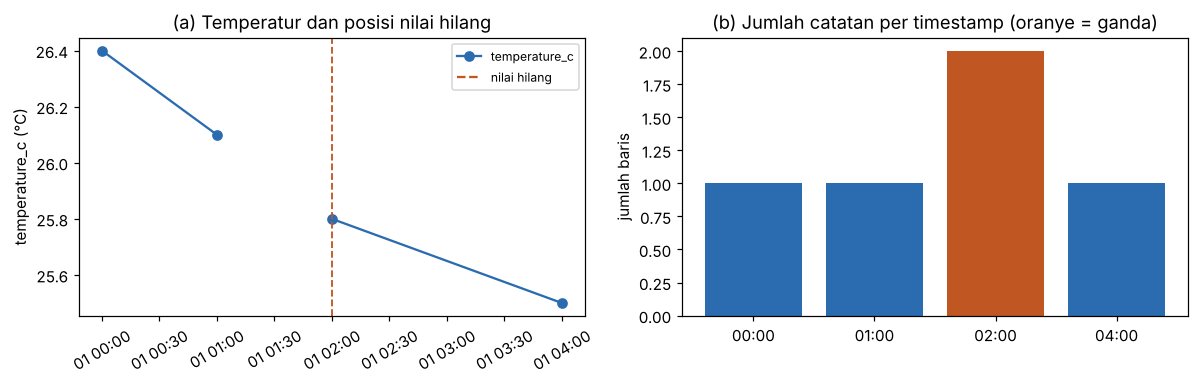

In [5]:
df_io = pd.read_csv(IO_INPUT)
t = pd.to_datetime(df_io["time"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].plot(t, df_io["temperature_c"], "o-", color="#2b6cb0", label="temperature_c")
hilang = df_io["temperature_c"].isna()
for xi in t[hilang]:
    ax[0].axvline(xi, color="#c05621", ls="--", lw=1.2)
ax[0].plot([], [], color="#c05621", ls="--", label="nilai hilang")
ax[0].set_title("(a) Temperatur dan posisi nilai hilang")
ax[0].set_ylabel("temperature_c (°C)"); ax[0].legend(fontsize=8)
ax[0].tick_params(axis="x", rotation=30)

jum = t.value_counts().sort_index()
ax[1].bar(jum.index.strftime("%H:%M"), jum.values, color=["#c05621" if v > 1 else "#2b6cb0" for v in jum.values])
ax[1].set_title("(b) Jumlah catatan per timestamp (oranye = ganda)")
ax[1].set_ylabel("jumlah baris")
plt.tight_layout(); plt.show()

### B.5.5 Run record `R-IO-001`

In [6]:
run_io = {
    "recipe_id": "R-IO-001", "prompt_id": "P-IO-001",
    "status": "Executed",
    "catatan_status": ("Dijalankan penuh pada fixture REKONSTRUKSI (5x4, 1 temperatur hilang, 1 pasangan timestamp ganda) "
                       "mengikuti deskripsi buku. Bukan fixture asli buku, bukan replika run record buku."),
    "waktu_eksekusi": pd.Timestamp.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": platform.python_version(), "numpy": np.__version__,
                   "pandas": pd.__version__, "os": platform.system()},
    "input": {"file": IO_INPUT, "sha256_sebelum": hash_sebelum, "sha256_sesudah": hash_sesudah},
    "output": {"laporan": REPORT_IO, "baris": temuan["baris"], "kolom": temuan["kolom"],
               "missing": temuan["missing_per_kolom"], "baris_timestamp_ganda": temuan["duplikat_timestamp_baris"]},
    "checks": checks_io,
}
with open("results/run-records/r-io-001.json", "w", encoding="utf-8") as f:
    json.dump(run_io, f, indent=2, ensure_ascii=False)

print(open(REPORT_IO, encoding="utf-8").read())

# Laporan QA/QC station CSV (R-IO-001)

- Input: `data/samples/station-example.csv`
- Jumlah baris data: 5; jumlah kolom: 4
- Rentang waktu: 2026-01-01 00:00:00 sampai 2026-01-01 04:00:00
- Timestamp gagal diparse: 0

## Missing value
- `time`: 0
- `station_id`: 0
- `temperature_c`: 1 (baris file: [4])
- `rainfall_mm`: 0

## Duplicate timestamp
- Baris file yang terlibat: [4, 5]

## Satuan terbaca dari nama kolom
- `temperature_c`: degC
- `rainfall_mm`: mm

## Ringkasan numerik

|       |   temperature_c |   rainfall_mm |
|:------|----------------:|--------------:|
| count |           4     |          5    |
| mean  |          25.95  |          0.32 |
| std   |           0.387 |          0.61 |
| min   |          25.5   |          0    |
| 25%   |          25.725 |          0    |
| 50%   |          25.95  |          0    |
| 75%   |          26.175 |          0.2  |
| max   |          26.4   |          1.4  |

## Status
Audit hanya melaporkan. Tidak ada baris dihapus, diubah, atau dii

**Apa yang saya pelajari dari Bagian B.**
- Menjalankan recipe sendiri memperlihatkan hal yang tidak tampak saat membaca: contohnya urusan *nomor baris* (baris data ke-3 di pandas adalah baris ke-4 di berkas karena ada header). Laporan yang memakai indeks pandas akan salah satu baris di mata orang yang membuka CSV-nya. Karena itu saya melaporkan nomor baris **berkas**.
- `duplicated(keep=False)` dipilih karena `keep="first"` hanya menandai salinan kedua, sehingga pasangan ganda terlihat sebagai satu baris.
- Audit yang *read-only* terbukti dengan bukti, bukan klaim: hash input identik sebelum dan sesudah.
- Keterbatasan: fixture hanya 5 baris. Tidak teruji untuk berkas besar, zona waktu campuran, atau kolom satuan yang tidak mengikuti konvensi akhiran nama.

---
# BAGIAN C. Recipe Buatan Sendiri: `R-SES-003`
## Menentukan *b-value* Gutenberg-Richter dan *magnitude of completeness* dari katalog gempa

**Mengapa topik ini?** Menentukan hiposenter (lokasi) adalah pertanyaan "di mana". Recipe ini menjawab pertanyaan berbeda pada katalog yang sama: **seberapa sering gempa kecil dibanding gempa besar, dan mulai dari magnitudo berapa katalog bisa dipercaya?** Ini algoritme dan data yang berbeda (statistik frekuensi-magnitudo, bukan inversi waktu tiba).

**Yang membuat recipe ini lebih lengkap dari contoh dasar di buku** (rinciannya dinilai di Bagian D):
1. **Gerbang kondisional** (`P1 ? P2 : P3`): bila data terlalu sedikit atau Mc tidak ditemukan, recipe **berhenti** dan menulis alasan, bukan memaksa keluar angka.
2. **Gerbang manusia** `[H]`: hasil ditandai belum boleh dipakai di luar latihan tanpa tinjauan.
3. **Dua penaksir dibandingkan** (Aki-Utsu *maximum likelihood* vs kuadrat terkecil pada kurva kumulatif) untuk menunjukkan bias metode yang populer tetapi kurang baik.
4. **Ketidakpastian dua cara** (rumus Shi dan Bolt vs *bootstrap*) yang harus saling cocok.
5. **Check dan toleransi ditulis di prompt sebelum run.**

## C.1 Problem
Diberikan katalog magnitudo gempa (satu kolom magnitudo per kejadian). Tentukan (a) **Mc**, magnitudo terkecil yang katalognya sudah lengkap, dan (b) **b-value** beserta ketidakpastiannya.

**Batas keputusan:** latihan memahami statistik katalog. **Bukan** penilaian bahaya seismik, bukan keputusan mitigasi.

## C.2 Minimal Theory
**Hukum Gutenberg-Richter.** Jumlah kejadian kumulatif dengan magnitudo ≥ M:

$$\log_{10} N(\ge M) = a - b\,M$$

`b` (kemiringan) kira-kira 1 untuk banyak katalog tektonik; nilai lebih besar berarti proporsi gempa kecil lebih tinggi.

**Magnitude of completeness (Mc).** Gempa kecil sering tak terdeteksi (stasiun kurang peka, noise). Di bawah Mc, kurva melandai dan **b terlihat lebih kecil dari yang sebenarnya**. Metode *maximum curvature* (MAXC) mengambil Mc sebagai magnitudo dengan jumlah kejadian per kelas **terbanyak** pada distribusi non-kumulatif. MAXC cenderung **meremehkan** Mc, sehingga praktik umum menambah koreksi sekitar +0,2 (Woessner dan Wiemer, 2005). Koreksi ini heuristik, bukan hukum.

**Penaksir Aki-Utsu (maximum likelihood), magnitudo dibulatkan ke kelas lebar ΔM:**

$$\hat b = \frac{\log_{10} e}{\bar M - \left(M_c - \Delta M/2\right)}$$

dengan $\bar M$ rata-rata magnitudo semua kejadian $M \ge M_c$. Suku $\Delta M/2$ adalah **koreksi pembulatan**: tanpa itu b bias rendah.

**Ketidakpastian (Shi dan Bolt, 1982):**

$$\sigma_b = 2{,}30\, \hat b^{2}\sqrt{\frac{\sum_i (M_i-\bar M)^2}{N(N-1)}}$$

**Asumsi dan keterbatasan.** (1) Satu b tunggal untuk seluruh wilayah dan waktu (kenyataan sering tidak). (2) Magnitudo seragam satu skala. (3) Kejadian independen: katalog dengan *aftershock* melanggar ini. (4) Katalog dianggap lengkap di atas Mc. (5) Pada data sintetis di sini, jawaban benar diketahui; pada data nyata tidak.

## C.3 Kontrak input dan constraint
| Hal | Aturan |
|---|---|
| Input | `results/r-ses-003/katalog_sintetis.csv`: kolom `event_id`, `magnitude` (dibulatkan 0,1) |
| Model | GR dengan b tunggal; kelas ΔM = 0,1 |
| Tidak boleh | Mengubah file input; membuang kejadian dari file; menjalankan bila N di atas Mc kurang dari 50 |
| Library | `numpy`, `pandas`, `matplotlib`. Tanpa jaringan |
| Output | `hasil_b_value.csv`, `fmd_tabel.csv`, `scan_mc.csv`, `sensitivitas.csv`, `fmd_b_value.png`, `run_record.json` di `results/r-ses-003/` |

## C.4 Prompt (`P-SES-003`)
```text
R (Role)        : Asisten analisis seismologi statistik dengan Python (numpy, pandas, matplotlib).
T (Task)        : Dari magnitudo di [CSV_PATH], tentukan Mc (maximum curvature + [KOREKSI_MC])
                  dan b-value (Aki-Utsu, kelas [DM]) dengan ketidakpastian 1-sigma (Shi-Bolt dan
                  bootstrap [N_BOOT]x). Bandingkan dengan kuadrat terkecil kurva kumulatif.
C (Context)     : Latihan Seismologi statistik. Bukan penilaian bahaya seismik.
I (Input)       : Hanya [CSV_PATH], kolom event_id dan magnitude. Magnitudo seragam satu skala,
                  dibulatkan ke [DM]. Tidak ada data lain.
K (Constraints) : Jangan ubah file input atau buang kejadian dari file. Jangan memilih Mc sendiri
                  di luar aturan MAXC+koreksi. Kalau N(M>=Mc) < [MIN_N], BERHENTI dan laporkan
                  alasannya (jangan keluarkan b). Hanya numpy, pandas, matplotlib. Tanpa jaringan.
O (Output)      : [OUTPUT_DIR]/hasil_b_value.csv, fmd_tabel.csv, scan_mc.csv,
                  sensitivitas.csv, fmd_b_value.png, run_record.json
Q (Quality)     : Lapor Mc, N di atas Mc, b +/- sigma (dua cara), selisih kedua sigma, hash input.
                  Pisahkan observasi, inferensi, keterbatasan. Tulis b dan sigma dengan 2 desimal.
V (Verification): Toleransi DITETAPKAN SEBELUM RUN:
                  (1) hash input sebelum = sesudah;  (2) N(M>=Mc) >= [MIN_N];
                  (3) hitung b manual dengan loop, selisih < 1e-9 dari fungsi;
                  (4) |b - b_acuan| < [TOL_B] (hanya data sintetis);
                  (5) CI bootstrap 95% memuat b_acuan (hanya data sintetis);
                  (6) sigma Shi-Bolt dan sd bootstrap berbeda < faktor 1,5;
                  (7) Mc terpilih dalam +/-0,5 dari kelengkapan efektif (hanya sintetis);
                  (8) b stabil (selisih maks < 0,3) untuk Mc, Mc+0,1 ... Mc+0,5.
                  Bila ada check gagal: status Partial, jangan diberi label Executed.
Gerbang [H]     : Hasil belum boleh dipakai di luar latihan sebelum ditinjau manusia.
```

## C.5 Code
### C.5.1 Setup dan parameter
Semua parameter ditetapkan di sini, termasuk toleransi, **sebelum** data dibuat dan sebelum hasil terlihat.

In [7]:
import os, json, hashlib, platform
from math import erf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT3 = "results/r-ses-003"
os.makedirs(OUT3, exist_ok=True)
CAT_PATH = os.path.join(OUT3, "katalog_sintetis.csv")

# --- parameter data sintetis (jawaban "benar" hanya ada karena kita yang membuat) ---
B_ACUAN   = 1.00     # b-value sebenarnya
DM        = 0.1      # lebar kelas magnitudo
M_MIN     = 0.5      # magnitudo terkecil yang dibangkitkan
N_AWAL    = 20000    # jumlah gempa sebelum pemotongan oleh deteksi
M50       = 1.6      # magnitudo dengan peluang terdeteksi 50%
SD_DET    = 0.25     # lebar kurva deteksi
MC_EFEKTIF = 2.2     # kira-kira di sini deteksi > 99% (acuan hanya untuk data sintetis)
SEED      = 2026

# --- parameter metode dan toleransi (ditetapkan SEBELUM run, sesuai prompt P-SES-003) ---
KOREKSI_MC = 0.2     # tambahan pada Mc hasil MAXC
MIN_N      = 50
N_BOOT     = 1000
TOL_B      = 0.2
RNG = np.random.default_rng(SEED)
print("Parameter siap. Output di:", OUT3)

Parameter siap. Output di: results/r-ses-003


### C.5.2 Membuat katalog sintetis dengan deteksi tidak lengkap
Kita bangkitkan gempa yang mengikuti hukum GR dengan b = 1,00 (magnitudo ≥ 0,5 berdistribusi eksponensial), lalu **buang sebagian gempa kecil** memakai kurva peluang deteksi. Hasilnya katalog yang **tidak lengkap di magnitudo kecil**, seperti katalog nyata. Pada kasus nyata, kita tidak mengetahui b sebenarnya maupun kurva deteksinya.

In [8]:
def cdf_normal(x):
    return 0.5 * (1.0 + np.array([erf(v / np.sqrt(2.0)) for v in np.atleast_1d(x)]))

beta = B_ACUAN * np.log(10.0)
m_kontinu = (M_MIN - DM / 2) + RNG.exponential(1.0 / beta, N_AWAL)   # kelas pertama berpusat di M_MIN
terdeteksi = RNG.random(N_AWAL) < cdf_normal((m_kontinu - M50) / SD_DET)
mag = np.round(m_kontinu[terdeteksi], 1)                              # dibulatkan 0,1 seperti katalog nyata

katalog = pd.DataFrame({"event_id": [f"EV{i:04d}" for i in range(1, len(mag) + 1)], "magnitude": mag})
katalog.to_csv(CAT_PATH, index=False)
print(f"Dibangkitkan {N_AWAL} gempa, terdeteksi {len(katalog)} ({100*len(katalog)/N_AWAL:.1f}%)")
katalog.head()

Dibangkitkan 20000 gempa, terdeteksi 1720 (8.6%)


,event_id,magnitude
0,EV0001,1.8
1,EV0002,1.6
2,EV0003,1.5
3,EV0004,1.8
4,EV0005,1.8


### C.5.3 Muat dan validasi input, lalu hitung hash
Data **dibaca ulang dari berkas**, seperti pada kasus nyata. Hash dihitung sekarang dan dibandingkan lagi di akhir.

In [9]:
def sha256_file(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

hash_cat_sebelum = sha256_file(CAT_PATH)
data = pd.read_csv(CAT_PATH)
mags_semua = data["magnitude"].to_numpy(float)

cek_input = {
    "kolom_lengkap": {"event_id", "magnitude"}.issubset(data.columns),
    "tidak_ada_nilai_hilang": int(data[["event_id", "magnitude"]].isna().sum().sum()) == 0,
    "magnitudo_berhingga": bool(np.isfinite(mags_semua).all()),
    "rentang_wajar(-2..10)": bool(((mags_semua > -2) & (mags_semua < 10)).all()),
    "id_unik": bool(data["event_id"].is_unique),
    "kelas_0.1": bool(np.allclose(mags_semua, np.round(mags_semua, 1))),
}
for k, v in cek_input.items():
    print(("LOLOS  " if v else "GAGAL  ") + k)
assert all(cek_input.values()), "Validasi input gagal: hentikan recipe."
print(f"\nJumlah kejadian: {len(data)} | magnitudo {mags_semua.min():.1f} sampai {mags_semua.max():.1f}")

LOLOS  kolom_lengkap
LOLOS  tidak_ada_nilai_hilang
LOLOS  magnitudo_berhingga
LOLOS  rentang_wajar(-2..10)
LOLOS  id_unik
LOLOS  kelas_0.1

Jumlah kejadian: 1720 | magnitudo 0.6 sampai 5.7


### C.5.4 Fungsi inti: FMD, Mc (MAXC), b Aki-Utsu, b kuadrat terkecil
Magnitudo diubah ke indeks bilangan bulat sebelum dihitung supaya perbandingan desimal tidak kacau (misalnya `2.3 == 2.3000000000000003`).

In [10]:
def fmd(mags, dm=DM):
    # Distribusi frekuensi-magnitudo: kelas, jumlah per kelas, jumlah kumulatif (>= kelas).
    k = np.round(mags / dm).astype(int)
    k0 = k.min()
    cnt = np.bincount(k - k0)
    bins = np.round((np.arange(len(cnt)) + k0) * dm, 1)
    cum = cnt[::-1].cumsum()[::-1]
    return bins, cnt, cum

def mc_maxc(bins, cnt):
    return float(bins[np.argmax(cnt)])

def b_aki(mags, mc, dm=DM):
    # b Aki-Utsu dengan koreksi pembulatan dan sigma Shi-Bolt.
    sel = mags[mags >= mc - 1e-9]
    n = len(sel)
    b = np.log10(np.e) / (sel.mean() - (mc - dm / 2))
    sigma = 2.30 * b**2 * np.sqrt(np.sum((sel - sel.mean())**2) / (n * (n - 1)))
    return float(b), float(sigma), int(n)

def b_lsq(bins, cum, mc):
    # b dari regresi log10(N kumulatif) terhadap M untuk M >= Mc (cara populer, cenderung bias).
    ok = (bins >= mc - 1e-9) & (cum > 0)
    slope, _ = np.polyfit(bins[ok], np.log10(cum[ok]), 1)
    return float(-slope)

bins, cnt, cum = fmd(mags_semua)
mc_dasar = mc_maxc(bins, cnt)
MC_PAKAI = round(mc_dasar + KOREKSI_MC, 1)
print(f"Mc (MAXC)         = {mc_dasar:.1f}")
print(f"Mc dipakai        = {MC_PAKAI:.1f}  (MAXC + koreksi {KOREKSI_MC})")

Mc (MAXC)         = 1.7
Mc dipakai        = 1.9  (MAXC + koreksi 0.2)


### C.5.5 Gerbang kondisional `[H]`
Sesuai prompt: bila jumlah kejadian di atas Mc kurang dari `MIN_N`, **berhenti dan tulis alasan**, bukan memaksa mengeluarkan b.

In [11]:
def gerbang(mags, mc, min_n=MIN_N):
    n = int((mags >= mc - 1e-9).sum())
    if n < min_n:
        return False, f"BERHENTI: hanya {n} kejadian dengan M >= {mc:.1f} (minimum {min_n}). b tidak dilaporkan."
    return True, f"LANJUT: {n} kejadian dengan M >= {mc:.1f} (minimum {min_n})."

lanjut, pesan = gerbang(mags_semua, MC_PAKAI)
print(pesan)

# Uji gerbangnya sendiri pada katalog sengaja dibuat kecil: harus BERHENTI
lanjut_uji, pesan_uji = gerbang(mags_semua[:40], MC_PAKAI)
print("Uji gerbang pada 40 kejadian pertama ->", pesan_uji)
assert lanjut and not lanjut_uji, "Gerbang tidak berfungsi sesuai rancangan."

LANJUT: 750 kejadian dengan M >= 1.9 (minimum 50).
Uji gerbang pada 40 kejadian pertama -> BERHENTI: hanya 17 kejadian dengan M >= 1.9 (minimum 50). b tidak dilaporkan.


### C.5.6 Taksiran b, dua penaksir, dan ketidakpastian

In [12]:
b_hat, sig_sb, n_atas = b_aki(mags_semua, MC_PAKAI)
b_kt = b_lsq(bins, cum, MC_PAKAI)

# Bootstrap: ambil ulang kejadian di atas Mc dengan pengembalian, hitung ulang b tiap kali
sel = mags_semua[mags_semua >= MC_PAKAI - 1e-9]
rata_boot = RNG.choice(sel, size=(N_BOOT, len(sel)), replace=True).mean(axis=1)
b_boot = np.log10(np.e) / (rata_boot - (MC_PAKAI - DM / 2))
sd_boot = float(b_boot.std(ddof=1))
ci_boot = np.percentile(b_boot, [2.5, 97.5])

print(f"N (M >= {MC_PAKAI:.1f})            : {n_atas}")
print(f"b Aki-Utsu                 : {b_hat:.3f} +/- {sig_sb:.3f} (Shi-Bolt)")
print(f"sd bootstrap               : {sd_boot:.3f} | CI 95% = [{ci_boot[0]:.3f}, {ci_boot[1]:.3f}]")
print(f"b kuadrat terkecil kumulatif: {b_kt:.3f}")

N (M >= 1.9)            : 750
b Aki-Utsu                 : 0.961 +/- 0.036 (Shi-Bolt)
sd bootstrap               : 0.036 | CI 95% = [0.896, 1.037]
b kuadrat terkecil kumulatif: 0.727


### C.5.7 Pindai Mc: seberapa sensitif b terhadap pilihan Mc?
Mc terlalu rendah memasukkan gempa yang terlewat deteksi dan **menurunkan** b. Pemindaian ini menampilkan efeknya.

In [13]:
baris = []
for mc in np.round(np.arange(1.0, 3.11, 0.1), 1):
    sel_mc = mags_semua[mags_semua >= mc - 1e-9]
    if len(sel_mc) < 30:
        continue
    b, s, n = b_aki(mags_semua, mc)
    baris.append({"Mc": mc, "N": n, "b_aki": round(b, 3), "sigma_shi_bolt": round(s, 3)})
scan = pd.DataFrame(baris)
scan.to_csv(os.path.join(OUT3, "scan_mc.csv"), index=False)
scan[(scan.Mc >= 1.2) & (scan.Mc <= 2.8)].reset_index(drop=True)

,Mc,N,b_aki,sigma_shi_bolt
0,1.2,1668,0.578,0.009
1,1.3,1615,0.644,0.012
2,1.4,1539,0.717,0.014
3,1.5,1438,0.797,0.018
4,1.6,1289,0.865,0.022
5,1.7,1130,0.933,0.027
6,1.8,931,0.956,0.032
7,1.9,750,0.961,0.036
8,2.0,609,0.976,0.042
9,2.1,483,0.970,0.047


### C.5.8 Uji sensitivitas: ukuran sampel dan metode
Satu hasil bisa kebetulan bagus, maka kita ulangi **300 kali** dengan katalog lengkap (di atas Mc = 2,0) berukuran N berbeda, lalu bandingkan galat b dua penaksir. Perhatikan kurva kuadrat terkecil: bias dan galatnya lebih besar, terutama untuk N kecil.

In [14]:
def simulasi(n, n_ulang=300, mc=2.0):
    err_aki, err_lsq = [], []
    for _ in range(n_ulang):
        m = np.round(mc - DM / 2 + RNG.exponential(1.0 / beta, n), 1)
        m = m[m >= mc - 1e-9]
        if len(m) < 3:
            continue
        b1, _, _ = b_aki(m, mc)
        bb, cn, cc = fmd(m)
        b2 = b_lsq(bb, cc, mc)
        err_aki.append(b1 - B_ACUAN); err_lsq.append(b2 - B_ACUAN)
    e1, e2 = np.array(err_aki), np.array(err_lsq)
    return {
        "N": n,
        "aki_bias": round(float(np.median(e1)), 3), "aki_galat_p90": round(float(np.percentile(np.abs(e1), 90)), 3),
        "lsq_bias": round(float(np.median(e2)), 3), "lsq_galat_p90": round(float(np.percentile(np.abs(e2), 90)), 3),
    }

sens = pd.DataFrame([simulasi(n) for n in [50, 100, 200, 400, 800]])
sens.to_csv(os.path.join(OUT3, "sensitivitas.csv"), index=False)
sens

,N,aki_bias,aki_galat_p90,lsq_bias,lsq_galat_p90
0,50,0.019,0.242,-0.058,0.421
1,100,-0.011,0.149,-0.065,0.324
2,200,0.006,0.121,-0.017,0.299
3,400,0.001,0.074,-0.024,0.261
4,800,-0.003,0.065,-0.019,0.202


**Cara membaca:** `bias` adalah median (b taksiran − b sebenarnya); positif berarti dilebihkan. `galat_p90` adalah besar galat mutlak pada 10% kasus terburuk. Galat p90 Aki-Utsu mengecil kira-kira mengikuti $1/\sqrt{N}$ (ciri penaksir yang konsisten). Kuadrat terkecil pada kurva kumulatif punya galat p90 jauh lebih besar dan menyusut lebih lambat, padahal bias mediannya kecil: masalahnya **kestabilan** (ekor kurva yang jarang dan saling bergantung), bukan semata bias rata-rata.

### C.5.9 Grafik hasil
Tiga panel, warna sama untuk objek yang sama: **biru** = Aki-Utsu / data, **oranye** = kuadrat terkecil / peringatan, **abu** = acuan.

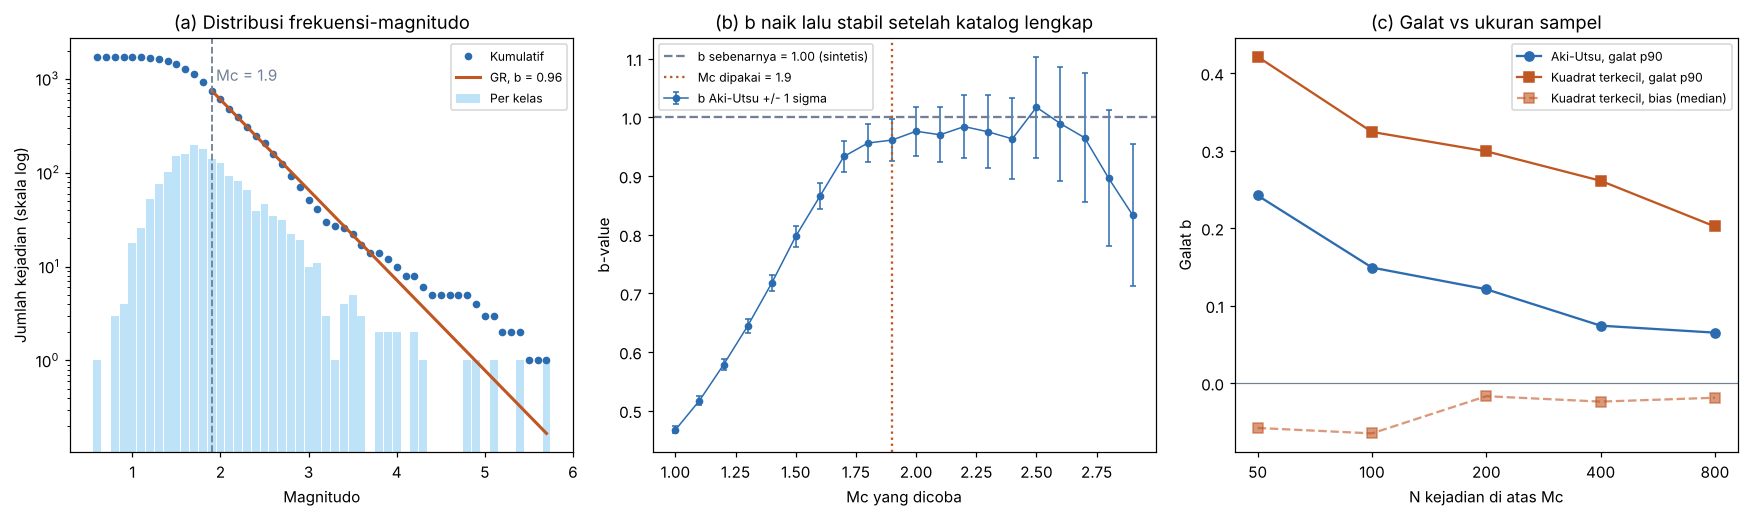

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
BIRU, ORANYE, ABU = "#2b6cb0", "#c05621", "#718096"

# (a) FMD
ax[0].bar(bins, cnt, width=DM * 0.9, color="#bee3f8", label="Per kelas")
ax[0].semilogy(bins[cum > 0], cum[cum > 0], "o", ms=4, color=BIRU, label="Kumulatif")
m_garis = np.linspace(MC_PAKAI, bins.max(), 50)
ax[0].semilogy(m_garis, n_atas * 10 ** (-b_hat * (m_garis - MC_PAKAI)), "-", color=ORANYE, lw=2,
               label=f"GR, b = {b_hat:.2f}")
ax[0].axvline(MC_PAKAI, color=ABU, ls="--", lw=1.2)
ax[0].text(MC_PAKAI + 0.05, ax[0].get_ylim()[1] * 0.35, f"Mc = {MC_PAKAI:.1f}", color=ABU)
ax[0].set_xlabel("Magnitudo"); ax[0].set_ylabel("Jumlah kejadian (skala log)")
ax[0].set_title("(a) Distribusi frekuensi-magnitudo"); ax[0].legend(fontsize=8)

# (b) scan Mc
s = scan[scan.Mc <= 2.9]
ax[1].errorbar(s.Mc, s.b_aki, yerr=s.sigma_shi_bolt, fmt="o-", color=BIRU, ms=4, lw=1, capsize=2, label="b Aki-Utsu +/- 1 sigma")
ax[1].axhline(B_ACUAN, color=ABU, ls="--", label=f"b sebenarnya = {B_ACUAN:.2f} (sintetis)")
ax[1].axvline(MC_PAKAI, color=ORANYE, ls=":", label=f"Mc dipakai = {MC_PAKAI:.1f}")
ax[1].set_xlabel("Mc yang dicoba"); ax[1].set_ylabel("b-value")
ax[1].set_title("(b) b naik lalu stabil setelah katalog lengkap"); ax[1].legend(fontsize=8)

# (c) sensitivitas
ax[2].semilogx(sens.N, sens.aki_galat_p90, "o-", color=BIRU, label="Aki-Utsu, galat p90")
ax[2].semilogx(sens.N, sens.lsq_galat_p90, "s-", color=ORANYE, label="Kuadrat terkecil, galat p90")
ax[2].semilogx(sens.N, sens.lsq_bias, "s--", color=ORANYE, alpha=0.6, label="Kuadrat terkecil, bias (median)")
ax[2].axhline(0, color=ABU, lw=0.8)
ax[2].set_xticks(sens.N); ax[2].set_xticklabels([str(n) for n in sens.N]); ax[2].minorticks_off()
ax[2].set_xlabel("N kejadian di atas Mc"); ax[2].set_ylabel("Galat b")
ax[2].set_title("(c) Galat vs ukuran sampel"); ax[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUT3, "fmd_b_value.png"), dpi=150)
plt.show()

### C.5.10 Menyimpan hasil

In [16]:
hasil = pd.DataFrame({
    "besaran": ["Mc_maxc", "Mc_dipakai", "N_di_atas_Mc", "b_aki_utsu", "sigma_shi_bolt",
                "sd_bootstrap", "ci95_bawah", "ci95_atas", "b_kuadrat_terkecil"],
    "nilai": [mc_dasar, MC_PAKAI, n_atas, b_hat, sig_sb, sd_boot, ci_boot[0], ci_boot[1], b_kt],
}).round(3)
hasil.to_csv(os.path.join(OUT3, "hasil_b_value.csv"), index=False)

fmd_tab = pd.DataFrame({"magnitudo": bins, "jumlah_per_kelas": cnt, "jumlah_kumulatif": cum})
fmd_tab.to_csv(os.path.join(OUT3, "fmd_tabel.csv"), index=False)
print(hasil.to_string(index=False))

           besaran   nilai
           Mc_maxc   1.700
        Mc_dipakai   1.900
      N_di_atas_Mc 750.000
        b_aki_utsu   0.961
    sigma_shi_bolt   0.036
      sd_bootstrap   0.036
        ci95_bawah   0.896
         ci95_atas   1.037
b_kuadrat_terkecil   0.727


---
## C.6 Result
Observasi (dihitung langsung), inferensi (tafsiran), dan keterbatasan dipisah.

In [17]:
galat_b = b_hat - B_ACUAN
print("OBSERVASI (dihitung dari data):")
print(f"- Katalog: {len(data)} kejadian. Mc (MAXC) = {mc_dasar:.1f}; Mc dipakai = {MC_PAKAI:.1f}; N(M>=Mc) = {n_atas}.")
print(f"- b Aki-Utsu = {b_hat:.2f} +/- {sig_sb:.2f} (Shi-Bolt); bootstrap sd = {sd_boot:.2f}, CI 95% = [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}].")
print(f"- b kuadrat terkecil kumulatif = {b_kt:.2f} (selisih {b_kt - b_hat:+.2f} terhadap Aki-Utsu).")
print(f"- Terhadap jawaban sebenarnya (hanya ada karena data sintetis): b sebenarnya = {B_ACUAN:.2f}, galat = {galat_b:+.2f}.")
rendah = scan[(scan.Mc >= 1.2) & (scan.Mc <= 1.4)]
print(f"- Bila Mc dipilih terlalu rendah (1,2 sampai 1,4), b turun ke {rendah.b_aki.min():.2f} sampai {rendah.b_aki.max():.2f}.")
print()
print("INFERENSI (tafsiran):")
print("- b yang naik lalu mendatar pada pemindaian Mc menunjukkan katalog menjadi lengkap di sekitar Mc yang dipilih.")
print("- Aki-Utsu lebih dekat ke nilai sebenarnya dan galatnya menyusut dengan N. Kuadrat terkecil pada kurva kumulatif galatnya")
print("  jauh lebih besar (panel c) dan pada katalog ini menyimpang 0,2 lebih rendah; ini hasil satu katalog, jadi tidak saya jadikan penaksir utama.")
print("- Dua cara menghitung ketidakpastian (rumus dan bootstrap) menunjuk skala yang sama, jadi sigma dapat dipercaya sebagai urutan besar.")
print()
print("KETERBATASAN:")
print("- Data sintetis dengan b tunggal dan kejadian independen. Katalog nyata punya aftershock, b yang berubah ruang dan waktu,")
print("  dan Mc yang berubah menurut waktu dan jaringan stasiun.")
print("- Koreksi Mc +0,2 adalah heuristik. Metode lain (misalnya goodness-of-fit) dapat memberi Mc berbeda.")
print("- 'Executed' di sini hanya berarti implementasi benar pada data sintetis, bukan bukti metode cocok untuk katalog tertentu.")
print("- Tidak untuk keputusan bahaya seismik. Gerbang [H]: tinjauan manusia diperlukan sebelum dipakai di luar latihan.")

OBSERVASI (dihitung dari data):
- Katalog: 1720 kejadian. Mc (MAXC) = 1.7; Mc dipakai = 1.9; N(M>=Mc) = 750.
- b Aki-Utsu = 0.96 +/- 0.04 (Shi-Bolt); bootstrap sd = 0.04, CI 95% = [0.90, 1.04].
- b kuadrat terkecil kumulatif = 0.73 (selisih -0.23 terhadap Aki-Utsu).
- Terhadap jawaban sebenarnya (hanya ada karena data sintetis): b sebenarnya = 1.00, galat = -0.04.
- Bila Mc dipilih terlalu rendah (1,2 sampai 1,4), b turun ke 0.58 sampai 0.72.

INFERENSI (tafsiran):
- b yang naik lalu mendatar pada pemindaian Mc menunjukkan katalog menjadi lengkap di sekitar Mc yang dipilih.
- Aki-Utsu lebih dekat ke nilai sebenarnya dan galatnya menyusut dengan N. Kuadrat terkecil pada kurva kumulatif galatnya
  jauh lebih besar (panel c) dan pada katalog ini menyimpang 0,2 lebih rendah; ini hasil satu katalog, jadi tidak saya jadikan penaksir utama.
- Dua cara menghitung ketidakpastian (rumus dan bootstrap) menunjuk skala yang sama, jadi sigma dapat dipercaya sebagai urutan besar.

KETERBATASAN:
- Dat

---
## C.7 Optional Check
Delapan check, toleransinya sudah tertulis di prompt (field V) **sebelum run**.

In [18]:
checks = {}

# 1. Input tidak berubah
hash_cat_sesudah = sha256_file(CAT_PATH)
checks["1_input_tidak_berubah(hash)"] = hash_cat_sebelum == hash_cat_sesudah

# 2. Jumlah kejadian di atas Mc memenuhi minimum
checks["2_N_di_atas_Mc>=MIN_N"] = n_atas >= MIN_N

# 3. Hitung b manual dengan loop (tanpa vektorisasi), bandingkan dengan fungsi
jumlah, cacah = 0.0, 0
for m_i in mags_semua:
    if m_i >= MC_PAKAI - 1e-9:
        jumlah += m_i; cacah += 1
b_manual = np.log10(np.e) / (jumlah / cacah - (MC_PAKAI - DM / 2))
checks["3_b_manual_sama_fungsi(<1e-9)"] = bool(abs(b_manual - b_hat) < 1e-9)
print(f"Check 3: b manual = {b_manual:.6f}, fungsi = {b_hat:.6f}")

# 4. Galat b terhadap acuan (hanya sintetis)
checks[f"4_|b-b_acuan|<{TOL_B}"] = bool(abs(galat_b) < TOL_B)

# 5. CI bootstrap memuat b acuan (hanya sintetis)
checks["5_CI_bootstrap_memuat_b_acuan"] = bool(ci_boot[0] <= B_ACUAN <= ci_boot[1])

# 6. Dua cara sigma sepakat dalam faktor 1,5
rasio = max(sig_sb, sd_boot) / min(sig_sb, sd_boot)
checks["6_sigma_ShiBolt~bootstrap(<1.5x)"] = bool(rasio < 1.5)
print(f"Check 6: sigma Shi-Bolt = {sig_sb:.3f}, sd bootstrap = {sd_boot:.3f}, rasio = {rasio:.2f}")

# 7. Mc terpilih dekat kelengkapan efektif (hanya sintetis)
checks["7_Mc_dalam_+-0.5_dari_efektif"] = bool(abs(MC_PAKAI - MC_EFEKTIF) <= 0.5)

# 8. Stabilitas b untuk Mc ... Mc+0,5
win = scan[(scan.Mc >= MC_PAKAI - 1e-9) & (scan.Mc <= MC_PAKAI + 0.5 + 1e-9)]
checks["8_b_stabil_Mc..Mc+0.5(<0.3)"] = bool(win.b_aki.max() - win.b_aki.min() < 0.3)
print(f"Check 8: b pada Mc..Mc+0.5 berkisar {win.b_aki.min():.2f} sampai {win.b_aki.max():.2f}")
print()
for k, v in checks.items():
    print(("LOLOS  " if v else "GAGAL  ") + k)

Check 3: b manual = 0.961112, fungsi = 0.961112
Check 6: sigma Shi-Bolt = 0.036, sd bootstrap = 0.036, rasio = 1.01
Check 8: b pada Mc..Mc+0.5 berkisar 0.96 sampai 0.98

LOLOS  1_input_tidak_berubah(hash)
LOLOS  2_N_di_atas_Mc>=MIN_N
LOLOS  3_b_manual_sama_fungsi(<1e-9)
LOLOS  4_|b-b_acuan|<0.2
LOLOS  5_CI_bootstrap_memuat_b_acuan
LOLOS  6_sigma_ShiBolt~bootstrap(<1.5x)
LOLOS  7_Mc_dalam_+-0.5_dari_efektif
LOLOS  8_b_stabil_Mc..Mc+0.5(<0.3)


---
## C.8 Run record
Status ditentukan oleh check, bukan oleh keinginan: semua lolos → `Executed` (pada data sintetis); ada yang gagal → `Partial`.

In [19]:
semua_lolos = all(checks.values())
run_record = {
    "recipe_id": "R-SES-003", "prompt_id": "P-SES-003",
    "status": "Executed" if semua_lolos else "Partial",
    "catatan_status": ("Dijalankan penuh pada data SINTETIS (b tunggal, kejadian independen). "
                       "Belum diuji pada katalog nyata. Tinjauan manusia [H] diperlukan sebelum dipakai di luar latihan."),
    "waktu_eksekusi": pd.Timestamp.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": platform.python_version(), "numpy": np.__version__,
                   "pandas": pd.__version__, "os": platform.system()},
    "input": {"file": CAT_PATH, "sha256_sebelum": hash_cat_sebelum, "sha256_sesudah": hash_cat_sesudah,
              "kejadian": int(len(data))},
    "parameter": {"dm": DM, "koreksi_mc": KOREKSI_MC, "min_n": MIN_N, "n_boot": N_BOOT,
                  "tol_b": TOL_B, "seed": SEED, "b_acuan": B_ACUAN, "mc_efektif_acuan": MC_EFEKTIF},
    "output": {"mc_dipakai": MC_PAKAI, "n_di_atas_mc": int(n_atas), "b_aki_utsu": round(b_hat, 3),
               "sigma_shi_bolt": round(sig_sb, 3), "sd_bootstrap": round(sd_boot, 3),
               "ci95_bootstrap": [round(float(ci_boot[0]), 3), round(float(ci_boot[1]), 3)],
               "b_kuadrat_terkecil": round(b_kt, 3),
               "file": ["hasil_b_value.csv", "fmd_tabel.csv", "scan_mc.csv", "sensitivitas.csv",
                        "fmd_b_value.png", "run_record.json"]},
    "gerbang": {"kondisional": pesan, "manusia": "Diperlukan sebelum hasil dipakai di luar latihan."},
    "checks": checks,
}
with open(os.path.join(OUT3, "run_record.json"), "w", encoding="utf-8") as f:
    json.dump(run_record, f, indent=2, ensure_ascii=False)
print(json.dumps(run_record, indent=2, ensure_ascii=False))
print("\nFile di", OUT3 + ":", sorted(os.listdir(OUT3)))

{
  "recipe_id": "R-SES-003",
  "prompt_id": "P-SES-003",
  "status": "Executed",
  "catatan_status": "Dijalankan penuh pada data SINTETIS (b tunggal, kejadian independen). Belum diuji pada katalog nyata. Tinjauan manusia [H] diperlukan sebelum dipakai di luar latihan.",
  "waktu_eksekusi": "2026-10-21T11:30:54",
  "lingkungan": {
    "python": "3.13.16",
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "os": "Linux"
  },
  "input": {
    "file": "results/r-ses-003/katalog_sintetis.csv",
    "sha256_sebelum": "b7912ad55eb5177afe3e2ac23833e05504dcff02724c97e8b07a26edff121bf3",
    "sha256_sesudah": "b7912ad55eb5177afe3e2ac23833e05504dcff02724c97e8b07a26edff121bf3",
    "kejadian": 1720
  },
  "parameter": {
    "dm": 0.1,
    "koreksi_mc": 0.2,
    "min_n": 50,
    "n_boot": 1000,
    "tol_b": 0.2,
    "seed": 2026,
    "b_acuan": 1.0,
    "mc_efektif_acuan": 2.2
  },
  "output": {
    "mc_dipakai": 1.9,
    "n_di_atas_mc": 750,
    "b_aki_utsu": 0.961,
    "sigma_shi_bolt": 0.036,
    

---
# BAGIAN D. Evaluasi dan Refleksi

## D.1 Rubrik 12 butir (dari A.8) diterapkan pada kedua recipe
Kolom bukti merujuk ke bagian notebook ini. Skor dihitung otomatis dari jumlah butir terpenuhi.

In [20]:
rubrik = [
    ("1  Problem sempit, satu outcome",                  True, True),
    ("2  Batas keputusan dinyatakan",                    True, True),
    ("3  Minimal theory: rumus, satuan, asumsi",         True, True),
    ("4  Kontrak input: path, skema, satuan",            True, True),
    ("5  Constraint dapat diuji",                        True, True),
    ("6  Prompt 8 field",                                True, True),
    ("7  Output contract",                               True, True),
    ("8  Check ditetapkan sebelum run + toleransi",      True, True),
    ("9  Pemeriksaan independen (cara kedua / manual)",  True, True),
    ("10 Observasi / inferensi / keterbatasan dipisah",  False, True),
    ("11 Run record (lingkungan, hash, check)",          True, True),
    ("12 Status bukti jujur",                            True, True),
]
nilai = pd.DataFrame(rubrik, columns=["Kriteria", "R-IO-001 (buku)", "R-SES-003 (milik sendiri)"])
for k in ["R-IO-001 (buku)", "R-SES-003 (milik sendiri)"]:
    nilai[k] = nilai[k].map({True: "ya", False: "tidak"})
print(nilai.to_string(index=False))
print()
print("Skor R-IO-001 :", (nilai["R-IO-001 (buku)"] == "ya").sum(), "/ 12")
print("Skor R-SES-003:", (nilai["R-SES-003 (milik sendiri)"] == "ya").sum(), "/ 12")

                                       Kriteria R-IO-001 (buku) R-SES-003 (milik sendiri)
                1  Problem sempit, satu outcome              ya                        ya
                  2  Batas keputusan dinyatakan              ya                        ya
       3  Minimal theory: rumus, satuan, asumsi              ya                        ya
          4  Kontrak input: path, skema, satuan              ya                        ya
                      5  Constraint dapat diuji              ya                        ya
                              6  Prompt 8 field              ya                        ya
                             7  Output contract              ya                        ya
    8  Check ditetapkan sebelum run + toleransi              ya                        ya
9  Pemeriksaan independen (cara kedua / manual)              ya                        ya
10 Observasi / inferensi / keterbatasan dipisah           tidak                        ya
        11

**Catatan penilaian.** Butir 10 pada `R-IO-001` saya beri "tidak" karena laporan audit murni menyajikan temuan dan tidak memuat pemisahan inferensi atau keterbatasan secara tertulis (itu wajar untuk audit, tetapi rubrik tetap menanyakannya). Skor ini penilaian diri saya, bukan penilaian pihak lain.

## D.2 Apa yang membedakan `R-SES-003` dari contoh recipe lokasi gempa

| Aspek | Contoh pembanding (hiposenter, Geiger) | `R-SES-003` (b-value) |
|---|---|---|
| Pertanyaan | **Di mana** dan **kapan** gempa terjadi | **Seberapa sering** gempa kecil vs besar; katalog lengkap mulai M berapa |
| Data | Waktu tiba P di 7 stasiun | Magnitudo ribuan kejadian, dengan deteksi tidak lengkap |
| Algoritme | Inversi linear iteratif + grid search | MAXC, Aki-Utsu (MLE), kuadrat terkecil, bootstrap |
| Cara verifikasi kedua | Grid search 3D | Hitung manual dengan loop; bootstrap vs rumus Shi-Bolt; dua penaksir |
| Struktur alur | Lurus: validasi → hitung → check | Ada **gerbang kondisional** yang berhenti bila data kurang, diuji sendiri |
| Toleransi | Di dalam kode check | Ditulis di **prompt (field V) sebelum run** |
| Status run record | `Executed` bila lolos | `Executed` / `Partial` ditentukan otomatis oleh check |
| Pesan pelajaran | RMS kecil bukan berarti lokasi benar | Mc terlalu rendah membuat b bias; kuadrat terkecil kumulatif jauh kurang stabil daripada Aki-Utsu |

## D.3 Refleksi
1. **Jarak antara membaca dan menjalankan.** Bagian B menunjukkan hal-hal kecil yang hanya muncul saat dikerjakan, seperti nomor baris berkas vs indeks pandas.
2. **Check sebelum run mengubah cara berpikir.** Menulis toleransi dulu memaksa saya menjawab "hasil seperti apa yang saya anggap benar?" sebelum melihat angka, sehingga check tidak bisa disesuaikan belakangan.
3. **Gerbang berhenti adalah fitur.** Recipe yang menolak mengeluarkan b saat data kurang lebih bisa dipercaya daripada yang selalu mengeluarkan angka.
4. **Batas bukti.** Semua yang lolos di notebook ini terbukti hanya untuk data sintetis (Bagian C) dan fixture rekonstruksi (Bagian B). Pada data nyata, langkah berikutnya adalah menjalankannya pada katalog sungguhan dengan tinjauan manusia di gerbang `[H]`.

## D.4 Struktur berkas yang dihasilkan

In [21]:
for root, dirs, files in os.walk("."):
    dirs[:] = sorted(d for d in dirs if not d.startswith((".", "__")))
    if root.startswith(("./data", "./results")) or root in (".", "./data", "./results"):
        for f in sorted(files):
            if root != "." and not f.endswith(".ipynb"):
                print(os.path.join(root, f))

./data/samples/station-example.csv
./results/io/station-summary.md
./results/r-ses-003/fmd_b_value.png
./results/r-ses-003/fmd_tabel.csv
./results/r-ses-003/hasil_b_value.csv
./results/r-ses-003/katalog_sintetis.csv
./results/r-ses-003/run_record.json
./results/r-ses-003/scan_mc.csv
./results/r-ses-003/sensitivitas.csv
./results/run-records/r-io-001.json


---
**Pustaka acuan:** buku *AI Cookbook untuk Earth Sciences*, Bab 2.1 sampai 2.6. Gutenberg dan Richter (1944) untuk hukum frekuensi-magnitudo; Aki (1965) dan Utsu (1965) untuk penaksir b; Shi dan Bolt (1982) untuk sigma b; Woessner dan Wiemer (2005) untuk Mc.